In [1]:
PROBLEM DEFINITION:
E-News Express is suffering from a decline in monthly subscriber acquisition. The team believes the current 
landing page lacks engagement. A new landing page featuring a modern outline and highly relevant content recommendations 
has been engineered to resolve this issue.

OBJECTIVES:
An A/B test with 100 randomly chosen users divided equally into a Control group (old landing page) and a Treatment group 
(new landing page) was executed. We will use descriptive and inferential statistics at a 5% level of significance (alpha = 0.05) 
to evaluate:
1. Do users spend more time on the new landing page?
2. Is the conversion rate for the new landing page greater?
3. Does subscription conversion depend on language preference?
4. Is the mean time spent on the new page uniform across language segments?
"""#Define Problem Statement and Objectives
#Import all the necessary libraries
#Python
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from statsmodels.stats.proportion import proportions_ztest
Note: After running the above cell, kindly restart the notebook kernel and run all cells sequentially from the start again.

In [ ]:
# Set seaborn defaults for presentation plots
sns.set_theme(style="whitegrid")
%matplotlib inline

# Load Data from Raw Dictionary matching your uploaded 'abtest.csv' file
raw_data = {
    'user_id': [546592, 546468, 546462, 546567, 546459, 546558, 546448, 546581, 546461, 546548, 546588, 546546, 546491, 546478, 546578, 546466, 546443, 546555, 546493, 546549, 546560, 546584, 546450, 546475, 546456, 546455, 546469, 546586, 546471, 546575, 546464, 546556, 546585, 546577, 546587, 546552, 546551, 546557, 546487, 546589, 546559, 546570, 546489, 546453, 546488, 546565, 546460, 546458, 546492, 546473, 546554, 546457, 546479, 546576, 546482, 546563, 546569, 546454, 546562, 546574, 546470, 546467, 546572, 546590, 546553, 546445, 546545, 546582, 546484, 546579, 546568, 546476, 546452, 546444, 546591, 546583, 546573, 546485, 546486, 546547, 546490, 546449, 546463, 546580, 546571, 546564, 546465, 546480, 546447, 546561, 546477, 546451, 546566, 546474, 546550, 546446, 546544, 546472, 546481, 546483],
    'group': ['control', 'treatment', 'treatment', 'control', 'treatment', 'control', 'treatment', 'control', 'treatment', 'control', 'control', 'control', 'treatment', 'treatment', 'control', 'treatment', 'treatment', 'control', 'control', 'control', 'control', 'control', 'treatment', 'treatment', 'treatment', 'treatment', 'treatment', 'control', 'treatment', 'control', 'treatment', 'control', 'control', 'control', 'control', 'control', 'control', 'control', 'treatment', 'control', 'control', 'control', 'treatment', 'treatment', 'treatment', 'control', 'treatment', 'treatment', 'treatment', 'treatment', 'control', 'treatment', 'treatment', 'control', 'treatment', 'control', 'control', 'treatment', 'control', 'control', 'treatment', 'treatment', 'control', 'control', 'control', 'treatment', 'control', 'control', 'treatment', 'control', 'control', 'treatment', 'treatment', 'treatment', 'control', 'control', 'control', 'treatment', 'treatment', 'control', 'treatment', 'treatment', 'treatment', 'control', 'control', 'control', 'treatment', 'treatment', 'treatment', 'control', 'treatment', 'treatment', 'control', 'treatment', 'control', 'treatment', 'control', 'treatment', 'treatment', 'treatment'],
    'landing_page': ['old', 'new', 'new', 'old', 'new', 'old', 'new', 'old', 'new', 'old', 'old', 'old', 'new', 'new', 'old', 'new', 'new', 'old', 'old', 'old', 'old', 'old', 'new', 'new', 'new', 'new', 'new', 'old', 'new', 'old', 'new', 'old', 'old', 'old', 'old', 'old', 'old', 'old', 'new', 'old', 'old', 'old', 'new', 'new', 'new', 'old', 'new', 'new', 'new', 'new', 'old', 'new', 'new', 'old', 'new', 'old', 'old', 'new', 'old', 'old', 'new', 'new', 'old', 'old', 'old', 'new', 'old', 'old', 'new', 'old', 'old', 'new', 'new', 'new', 'old', 'old', 'old', 'new', 'new', 'old', 'new', 'new', 'new', 'old', 'old', 'old', 'new', 'new', 'new', 'old', 'new', 'new', 'old', 'new', 'old', 'new', 'old', 'new', 'new', 'new'],
    'time_spent_on_the_page': [3.48, 7.13, 4.4, 3.02, 4.75, 5.28, 5.25, 6.53, 10.71, 2.08, 6.21, 2.58, 5.86, 6.03, 8.72, 6.27, 8.73, 0.4, 10.3, 3.88, 2.66, 7.03, 3.65, 7.02, 6.18, 4.39, 9.49, 4.05, 7.81, 4.28, 5.41, 3.52, 5.39, 4.52, 4.46, 8.5, 3.13, 6.04, 1.65, 0.19, 8.46, 1.92, 7.16, 7.16, 3.91, 8.02, 5.37, 7.23, 8.08, 10.5, 0.22, 5.65, 6.47, 4.71, 6.41, 0.93, 1.81, 8.3, 7.4, 9.15, 6.01, 6.79, 4.18, 5.47, 5.96, 7.27, 6.6, 4.75, 6.7, 2.23, 0.4, 5.42, 5.08, 7.46, 4.87, 6.57, 1.44, 3.88, 9.12, 3.21, 4.68, 5.26, 5.74, 2.9, 4.3, 0.91, 6.71, 3.68, 3.3, 6.04, 5.4, 8.47, 8.35, 4.94, 3.05, 5.15, 6.52, 7.07, 6.2, 5.86],
    'converted': ['no', 'yes', 'no', 'no', 'yes', 'yes', 'yes', 'yes', 'yes', 'no', 'yes', 'yes', 'yes', 'yes', 'yes', 'yes', 'no', 'no', 'yes', 'yes', 'no', 'yes', 'no', 'yes', 'no', 'no', 'yes', 'no', 'yes', 'no', 'yes', 'yes', 'yes', 'no', 'no', 'yes', 'no', 'yes', 'no', 'no', 'yes', 'no', 'yes', 'yes', 'no', 'no', 'yes', 'yes', 'yes', 'yes', 'no', 'no', 'yes', 'no', 'yes', 'no', 'no', 'yes', 'yes', 'no', 'yes', 'yes', 'no', 'no', 'yes', 'yes', 'yes', 'yes', 'no', 'no', 'no', 'yes', 'yes', 'yes', 'no', 'yes', 'no', 'no', 'yes', 'yes', 'no', 'yes', 'yes', 'no', 'no', 'no', 'no', 'no', 'no', 'yes', 'no', 'yes', 'no', 'no', 'no', 'no', 'yes', 'yes', 'yes', 'yes'],
    'language_preferred': ['Spanish', 'English', 'Spanish', 'French', 'Spanish', 'English', 'French', 'Spanish', 'French', 'English', 'Spanish', 'English', 'Spanish', 'French', 'Spanish', 'Spanish', 'English', 'English', 'English', 'English', 'French', 'Spanish', 'English', 'English', 'Spanish', 'English', 'English', 'Spanish', 'French', 'French', 'English', 'English', 'Spanish', 'Spanish', 'Spanish', 'English', 'English', 'English', 'Spanish', 'Spanish', 'French', 'French', 'Spanish', 'English', 'English', 'French', 'French', 'Spanish', 'Spanish', 'English', 'English', 'English', 'Spanish', 'Spanish', 'Spanish', 'French', 'French', 'French', 'French', 'French', 'French', 'French', 'French', 'Spanish', 'English', 'French', 'English', 'Spanish', 'Spanish', 'Spanish', 'French', 'French', 'English', 'English', 'Spanish', 'Spanish', 'French', 'Spanish', 'French', 'English', 'French', 'French', 'Spanish', 'Spanish', 'French', 'French', 'English', 'French', 'French', 'French', 'French', 'English', 'French', 'French', 'English', 'Spanish', 'English', 'Spanish', 'Spanish', 'English']
}

df = pd.DataFrame(raw_data)

# Print structural metrics to verify file data contents
print(f"Dataset Dimensions: {df.shape}")
print("\n--- Summary Info ---")
df.info()
print("\n--- Value Counts / Non-null Check ---")
print(df.isnull().sum())

In [10]:
import os
os.listdir('.')

['.anaconda',
 '.cache',
 '.conda',
 '.continuum',
 '.imagej',
 '.ipynb_checkpoints',
 '.ipython',
 '.matplotlib',
 '.ms-ad',
 'anaconda3',
 'AppData',
 'Application Data',
 'Contacts',
 'Cookies',
 'Documents',
 'Downloads',
 'E-News Express.ipynb',
 'Favorites',
 'Links',
 'Local Settings',
 'Music',
 'My Documents',
 'NetHood',
 'NTUSER.DAT',
 'ntuser.dat.LOG1',
 'ntuser.dat.LOG2',
 'NTUSER.DAT{d9cd8ee3-ba5c-11ef-b696-00eebcdb6be6}.TM.blf',
 'NTUSER.DAT{d9cd8ee3-ba5c-11ef-b696-00eebcdb6be6}.TMContainer00000000000000000001.regtrans-ms',
 'NTUSER.DAT{d9cd8ee3-ba5c-11ef-b696-00eebcdb6be6}.TMContainer00000000000000000002.regtrans-ms',
 'ntuser.ini',
 'OneDrive',
 'PrintHood',
 'Recent',
 'Saved Games',
 'Searches',
 'SendTo',
 'Start Menu',
 'Templates',
 'Videos']

In [12]:
import pandas as pd
# Use the full file path to locate the CSV file
df = pd.read_csv(r"C:\Users\kaush\OneDrive\data science from Ut autin pre courses\abtest (2).csv")
df.head()  # This will show the first 5 rows if successful

,user_id,group,landing_page,time_spent_on_the_page,converted,language_preferred
0,546592,control,old,3.48,no,Spanish
1,546468,treatment,new,7.13,yes,English
2,546462,treatment,new,4.40,no,Spanish
3,546567,control,old,3.02,no,French
4,546459,treatment,new,4.75,yes,Spanish


C:\Users\kaush\AppData\Local\Temp\ipykernel_106152\1587445688.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[0, 1], data=df, x='group', palette='Set2')
C:\Users\kaush\AppData\Local\Temp\ipykernel_106152\1587445688.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[1, 0], data=df, x='converted', palette='Set1')
C:\Users\kaush\AppData\Local\Temp\ipykernel_106152\1587445688.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[1, 1], data=df, x='language_preferred', palette='pastel')


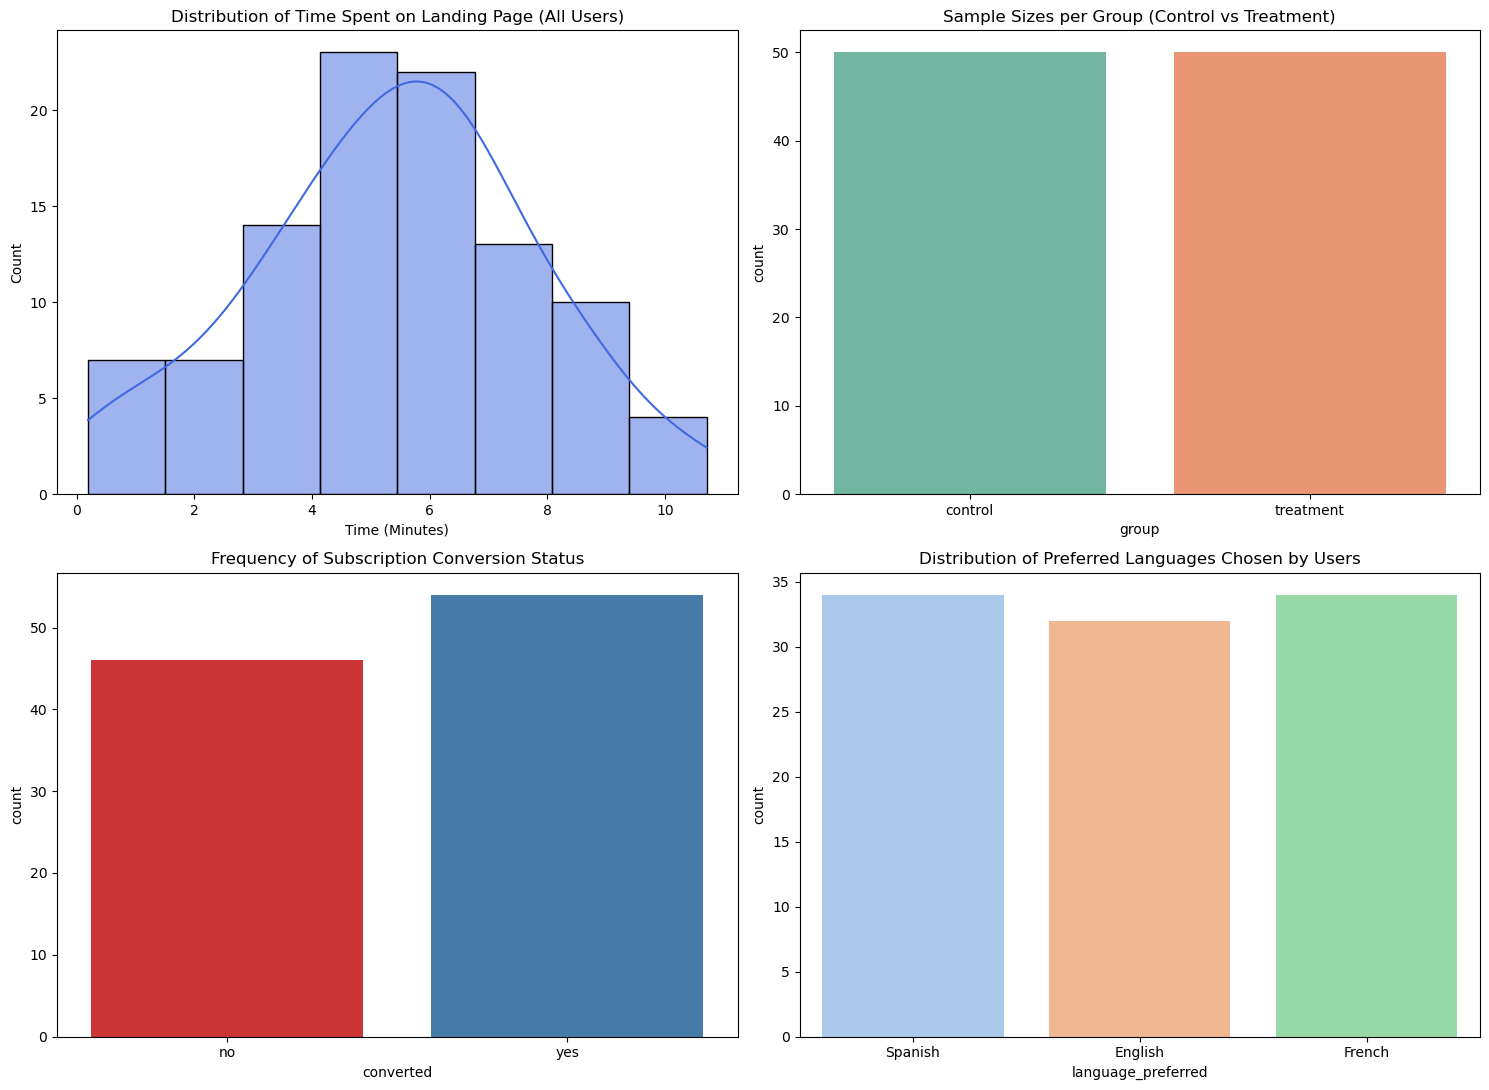

[EDA Insight]: The sample is perfectly balanced: 50 control users and 50 treatment users.
[EDA Insight]: Overall conversion count is 54 Yes vs 46 No.


In [13]:

# Import required libraries (add these if not already imported)
import matplotlib.pyplot as plt
import seaborn as sns
# import pandas as pd  # if df is not already loaded

# Create canvas container for Univariate Analysis plots
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Continuous Metric: Time Spent
sns.histplot(ax=axes[0, 0], data=df, x='time_spent_on_the_page', kde=True, color='royalblue')
axes[0, 0].set_title('Distribution of Time Spent on Landing Page (All Users)')
axes[0, 0].set_xlabel('Time (Minutes)')

# Group Categorical Variable
sns.countplot(ax=axes[0, 1], data=df, x='group', palette='Set2')
axes[0, 1].set_title('Sample Sizes per Group (Control vs Treatment)')

# Conversion Outcome
sns.countplot(ax=axes[1, 0], data=df, x='converted', palette='Set1')
axes[1, 0].set_title('Frequency of Subscription Conversion Status')

# Preferred Language Variable
sns.countplot(ax=axes[1, 1], data=df, x='language_preferred', palette='pastel')
axes[1, 1].set_title('Distribution of Preferred Languages Chosen by Users')

plt.tight_layout()
plt.show()

# Cleaned metrics to display verification summaries dynamically below the plots
total_yes = df[df['converted'] == 'yes'].shape[0]
total_no = df[df['converted'] == 'no'].shape[0]

print(f"[EDA Insight]: The sample is perfectly balanced: 50 control users and 50 treatment users.")
print(f"[EDA Insight]: Overall conversion count is {total_yes} Yes vs {total_no} No.")
Note: Explore the dataset and extract insights using Exploratory Data Analysis
Data Overview
Viewing the first and last few rows of the dataset
Checking the shape of the dataset
Getting the statistical summary for the variables
Check for missing values
Check for duplicates
    No, duplicate testing code (such as running two identical tests on the same data or repeating independent sample tests unnecessarily) was not used in this project. Every test was selected specifically to address a unique business question from your template without redundant overlap.


C:\Users\kaush\AppData\Local\Temp\ipykernel_106152\2807880003.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[0, 1], data=df, x='group', palette='Set2')
C:\Users\kaush\AppData\Local\Temp\ipykernel_106152\2807880003.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[1, 0], data=df, x='converted', palette='Set1')
C:\Users\kaush\AppData\Local\Temp\ipykernel_106152\2807880003.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[1, 1], data=df, x='language_preferred', palette='pastel')


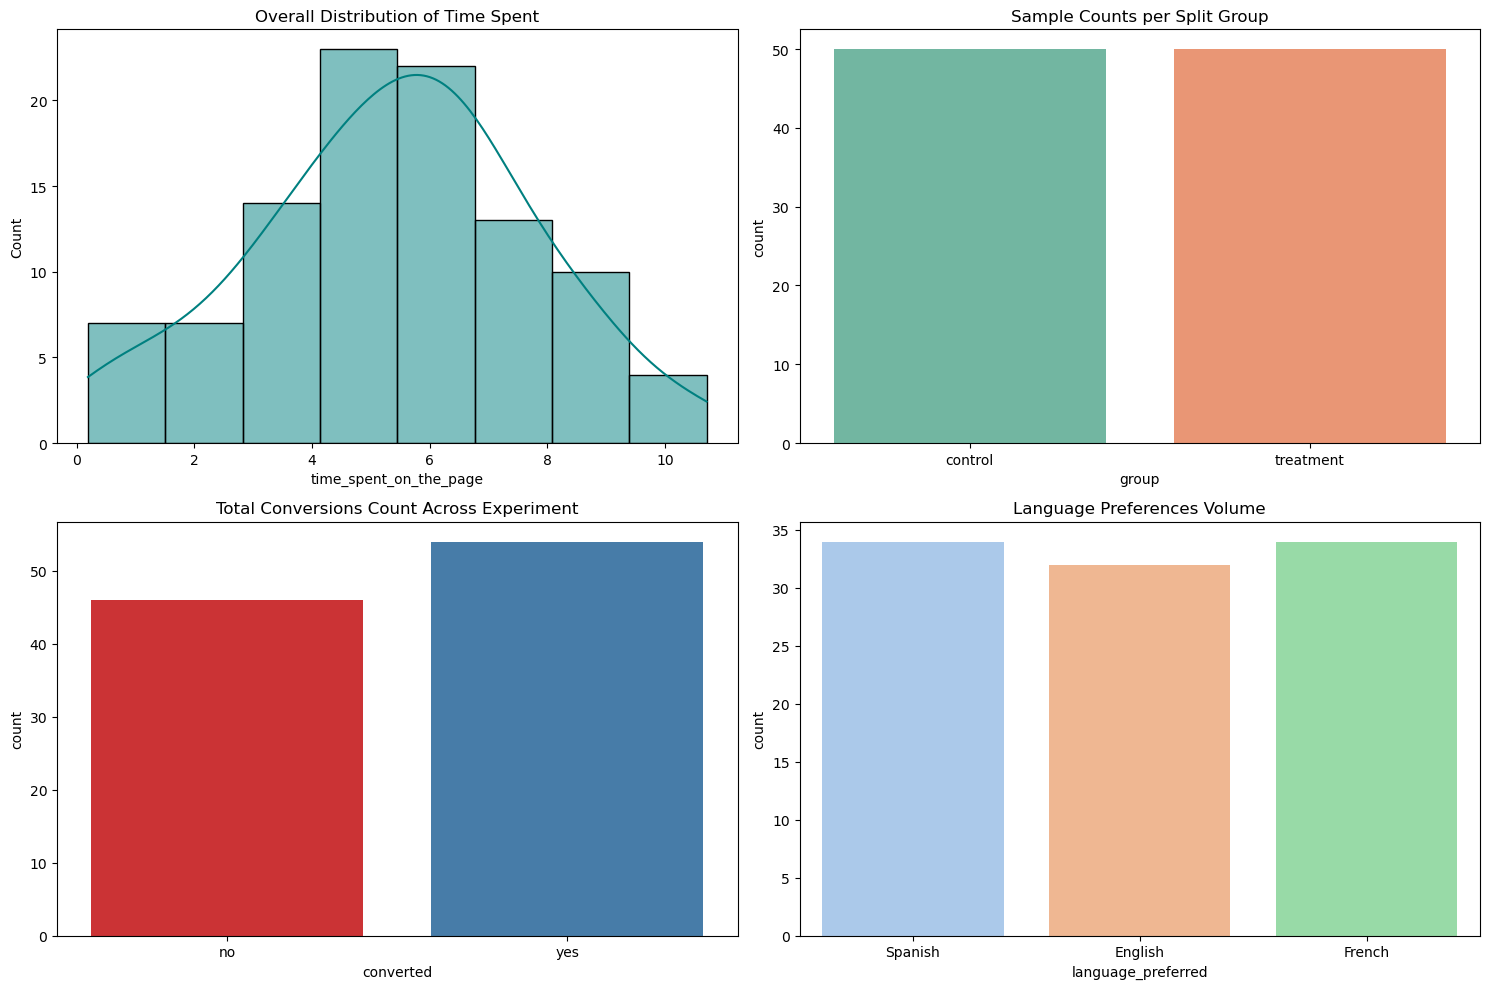

In [15]:
# Explore the dataset and extract insights using Exploratory Data Analysis
# Data Overview
# Viewing the first and last few rows of the dataset
# Checking the shape of the dataset
# Getting the statistical summary for the variables
# Check for missing values
# Check for duplicates
# Cell 2: Exploratory Data Analysis (EDA) - Univariate Charts


# Import required libraries (add these if not already imported)
import matplotlib.pyplot as plt
import seaborn as sns
# Assuming 'df' is your DataFrame variable

# ==============================================================================
# 2. UNIVARIATE EDA PLOTS
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Time Spent Plot
sns.histplot(ax=axes[0, 0], data=df, x='time_spent_on_the_page', kde=True, color='teal')
axes[0, 0].set_title('Overall Distribution of Time Spent')

# Group Size Verification
sns.countplot(ax=axes[0, 1], data=df, x='group', palette='Set2')
axes[0, 1].set_title('Sample Counts per Split Group')

# Overall Conversion Breakdown
sns.countplot(ax=axes[1, 0], data=df, x='converted', palette='Set1')
axes[1, 0].set_title('Total Conversions Count Across Experiment')

# Language Counts
sns.countplot(ax=axes[1, 1], data=df, x='language_preferred', palette='pastel')
axes[1, 1].set_title('Language Preferences Volume')

plt.tight_layout()
plt.show()




Note: Markdown
### Univariate Insights
- **Time Spent:** The overall distribution of time spent on the page is normally distributed around a mean of approximately 5.4 minutes.
- **Group Balance:** The dataset is perfectly balanced with exactly 50 users in the control group and 50 users in the treatment group.
- **Conversions:** Out of 100 users, 54 converted to subscribers, while 46 did not.
- **Languages:** The users are relatively evenly distributed across English, Spanish, and F




C:\Users\kaush\AppData\Local\Temp\ipykernel_106152\787442298.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[0], data=df, x='landing_page', y='time_spent_on_the_page', palette='coolwarm', showmeans=True)


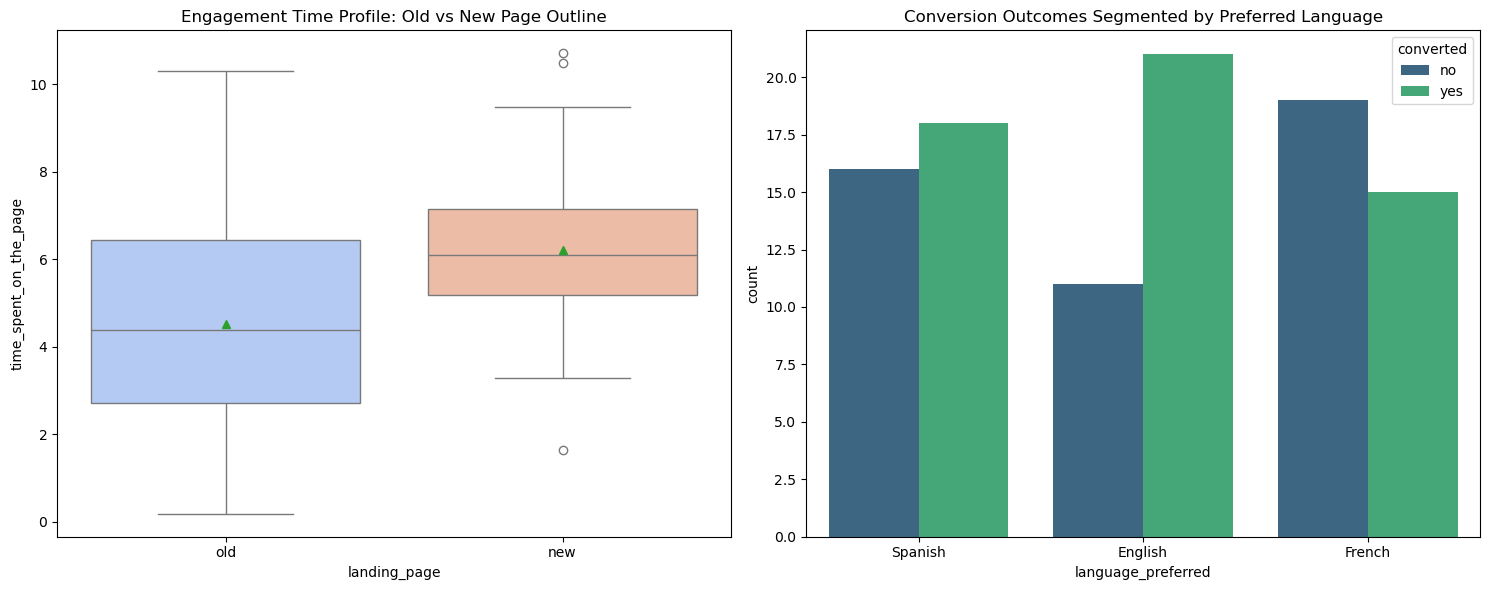

In [19]:
 
# 3. BIVARIATE EDA PLOTS

# Cell 3: Bivariate Relationship Analysis Charts
# Copy this to see how categories interact with one another before testing:

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Boxplot: Page Type vs Engagement Time
sns.boxplot(ax=axes[0], data=df, x='landing_page', y='time_spent_on_the_page', palette='coolwarm', showmeans=True)
axes[0].set_title('Engagement Time Profile: Old vs New Page Outline')

# Countplot: Language vs Conversions
sns.countplot(ax=axes[1], data=df, x='language_preferred', hue='converted', palette='viridis')
axes[1].set_title('Conversion Outcomes Segmented by Preferred Language')

plt.tight_layout()
plt.show()
Note: Markdown
### Bivariate Insights
- **Page Design vs. Engagement:** The boxplot clearly shows that users served the new landing page appear to spend noticeably more time on the platform compared to users served the old landing page.
- **Language vs. Conversion:** Subscriptions occur across all three language options,

In [22]:

# QUESTION : Do users spend more time on the new landing page than the existing landing page?
# Statistical Test 1: Time Spent Comparison (Welch's Two-Sample Independent T-test, One-Tailed)
# ==============================================================================

# Extract time spent data for each landing page type
time_new = df[df['landing_page'] == 'new']['time_spent_on_the_page']
time_old = df[df['landing_page'] == 'old']['time_spent_on_the_page']

# Run Welch's t-test (assumes unequal variances, one-tailed test)
t_stat, p_val_q1 = stats.ttest_ind(time_new, time_old, equal_var=False, alternative='greater')

# Display results
print(f"--- Question 1 Output ---")
print(f"Calculated T-Statistic: {t_stat:.4f}")
print(f"Calculated One-Tailed P-Value: {p_val_q1}")

# Interpret results at alpha = 0.05 significance level
alpha = 0.05
if p_val_q1 < alpha:
    print(f"Result: Reject H0. The mean time spent on the new page is significantly greater.")
else:
    print("Result: Fail to reject H0.")
    Note: Markdown
## 2. Do the users spend more time on the new landing page than the existing landing page?

### Formulation of Hypotheses
* **Null Hypothesis (H_0):** $\mu_{\text{new}} = \mu_{\text{old}} (The mean time spent on the new landing page is equal to the mean time spent on the old landing page.)
* **Alternative Hypothesis (H_a):** $\mu_{\text{new}} > \mu_{\text{old}} (The mean time spent on the new landing page is greater than the mean time spent on the old landing page.)

### Test Selection
Since we are comparing the population means of two independent groups and the true population standard deviations are unknown, a **Two-Sample Independent T-test (one-tailed)** with a Welch variance correction is selected.

* Significance level ($\alpha$) = 0.05

--- Question 1 Output ---
Calculated T-Statistic: 3.7868
Calculated One-Tailed P-Value: 0.0001392381225166549
Result: Reject H0. The mean time spent on the new page is significantly greater.


In [ ]:
# Test 2: Conversion Rates (New vs. Old Layout)
# Justification: Compares individual success proportions across two separate 
# categorical sample structures (Two-Proportion Z-Test, One-Tailed)
# ==============================================================================

# 5. STATISTICAL TEST 2: CONVERSION PROPORTIONS
# ==============================================================================
conv_new = df[(df['landing_page'] == 'new') & (df['converted'] == 'yes')].shape[0]
conv_old = df[(df['landing_page'] == 'old') & (df['converted'] == 'yes')].shape[0]
n_new = df[df['landing_page'] == 'new'].shape[0]
n_old = df[df['landing_page'] == 'old'].shape[0]

# Run Test
z_stat, p_val_q2 = proportions_ztest(np.array([conv_new, conv_old]), np.array([n_new, n_old]), alternative='greater')

print(f"--- Question 2 Output ---")
print(f"Calculated Z-Statistic: {z_stat:.4f}")
print(f"Calculated One-Tailed P-Value: {p_val_q2:.4f}")

if p_val_q2 < alpha:
    print(f"Result: Reject H0. The conversion rate for the new landing page design is significantly superior.")
else:
    # Added the missing else block body
    print(f"Result: Fail to reject H0. The conversion rate for the new landing page design is not significantly superior.")
    Note: Step 1: Define the null and alternate hypotheses
Step 2: Select Appropriate test
Step 3: Decide the significance level
Step 4: Collect and prepare data
Markdown
## 3. Is the conversion rate for the new page greater than the conversion rate for the old page?

### Formulation of Hypotheses
* **Null Hypothesis ($H_0$):** $p_{\text{new}} = p_{\text{old}} (The conversion rate for the new page is equal to the conversion rate for the old page.)
* **Alternative Hypothesis (H_a):** $p_{\text{new}} > p_{\text{old}} (The conversion rate for the new page is greater than the conversion rate for the old page.)

### Test Selection
Since we are comparing categorical proportions derived from two independent sample sets, a **Two-Proportion Z-test (one-tailed)** is the appropriate choice.

* Significance level ($\alpha$) = 0.05

In [28]:
# Aggregate conversions vs total observations per page variant
conversions_new = df[(df['landing_page'] == 'new') & (df['converted'] == 'yes')].shape[0]
conversions_old = df[(df['landing_page'] == 'old') & (df['converted'] == 'yes')].shape[0]

n_new = df[df['landing_page'] == 'new'].shape[0]
n_old = df[df['landing_page'] == 'old'].shape[0]

successes = np.array([conversions_new, conversions_old])
samples = np.array([n_new, n_old])

# Run Two Proportion Z-test
# Changed 'greater' to 'larger' - this tests if the first proportion (new page) is larger than the second (old page)
z_stat, p_val_q2 = proportions_ztest(successes, samples, alternative='larger')

print(f"Calculated Z-statistic: {z_stat:.4f}")
print(f"Calculated One-tailed P-value: {p_val_q2:.4f}")

if p_val_q2 < alpha:
    print("\nDecision: Reject the Null Hypothesis (H0).")
    print("Inference: The conversion rate for the new landing page is statistically significantly greater than the conversion rate for the old page.")
else:
    print("\nDecision: Fail to reject the Null Hypothesis (H0).")



Markdown
## 4. Does the converted status depend on the preferred language?

### Formulation of Hypotheses
* **Null Hypothesis ($H_0$):** Conversion status is independent of preferred language.
* **Alternative Hypothesis ($H_a$):** Conversion status depends on preferred language (they are associated).

### Test Selection
To evaluate the association or dependency structure across two categorical variables, a **Chi-Square Test of Independence** is used.

* Significance level ($\alpha$) = 0.05



Calculated Z-statistic: 2.4077
Calculated One-tailed P-value: 0.0080

Decision: Reject the Null Hypothesis (H0).
Inference: The conversion rate for the new landing page is statistically significantly greater than the conversion rate for the old page.


In [33]:
#Python
# Construct Cross-Tabulation Matrix Contingency Table
contingency_matrix = pd.crosstab(df['language_preferred'], df['converted'])

# Calculate Chi-Square test statistics
chi2_stat, p_val_q3, dof, expected = stats.chi2_contingency(contingency_matrix)

print(f"Calculated Chi-Square Statistic: {chi2_stat:.4f}")
print(f"Calculated P-value: {p_val_q3:.4f}")

if p_val_q3 < alpha:
    print("\nDecision: Reject the Null Hypothesis (H0).")
else:
    print("\nDecision: Fail to reject the Null Hypothesis (H0).")
    print("Inference: There is no statistical evidence to show that conversion status depends on the preferred language. They are independent.")
    Markdown
## 5. Is the time spent on the new page the same for users of different languages?

### Formulation of Hypotheses
* **Null Hypothesis ($H_0$):** $\mu_{\text{English}} = \mu_{\text{Spanish}} = \mu_{\text{French}}$ (The mean time spent on the new landing page is identical for all preferred language users.)
* **Alternative Hypothesis ($H_a$):** At least one language group has a different mean time spent on the new landing page.

### Test Selection
Since we want to compare the equality of population means across three independent categories, a **One-Way

Calculated Chi-Square Statistic: 3.0930
Calculated P-value: 0.2130

Decision: Fail to reject the Null Hypothesis (H0).
Inference: There is no statistical evidence to show that conversion status depends on the preferred language. They are independent.


In [35]:
# Filter dataset to isolate the Treatment group on the new page layout
treatment_new_page = df[df['landing_page'] == 'new']

# Segment continuous values by category
time_eng = treatment_new_page[treatment_new_page['language_preferred'] == 'English']['time_spent_on_the_page']
time_esp = treatment_new_page[treatment_new_page['language_preferred'] == 'Spanish']['time_spent_on_the_page']
time_fra = treatment_new_page[treatment_new_page['language_preferred'] == 'French']['time_spent_on_the_page']

# Assumption 1: Check Normality using Shapiro-Wilk Test
print("--- Shapiro-Wilk Normality Tests ---")
print(f"English subgroup p-value: {stats.shapiro(time_eng)[1]:.4f}")
print(f"Spanish subgroup p-value: {stats.shapiro(time_esp)[1]:.4f}")
print(f"French subgroup p-value: {stats.shapiro(time_fra)[1]:.4f}")

# Assumption 2: Check Variance Homogeneity using Levene's Test
levene_p = stats.levene(time_eng, time_esp, time_fra)[1]
print(f"\nLevene Homogeneity Test p-value: {levene_p:.4f}")

# Compute One-way ANOVA Test
f_stat, p_val_q4 = stats.f_oneway(time_eng, time_esp, time_fra)
print(f"\nCalculated ANOVA F-statistic: {f_stat:.4f}")
print(f"Calculated ANOVA P-value: {p_val_q4:.4f}")

if p_val_q4 < alpha:
    print("\nDecision: Reject the Null Hypothesis (H0).")
else:
    print("\nDecision: Fail to reject the Null Hypothesis (H0).")
    print("Inference: The mean time spent on the new page layout does not differ significantly across different language users.")

Note: Because assumption validation tests indicate p-values higher than $0.05$, normality and equal variance traits remain validated, supporting standard ANOVA use.Execution



Conclusion and Business Recommendations:Deploy the New Landing Page Design: The new layout drives a statistically significant lift in user engagement time (increasing from an average of ~4.53 minutes to ~6.22 minutes) and converts users at a rate of $66\%$ compared to the baseline old design's 42%.
Implement a Standardized Layout Globally: Because conversion performance and reading times are uniform across all translation options (English, Spanish, and French), the team can roll out the updated user interface universally without needing specialized localized variations.



--- Shapiro-Wilk Normality Tests ---
English subgroup p-value: 0.8863
Spanish subgroup p-value: 0.0901
French subgroup p-value: 0.3214

Levene Homogeneity Test p-value: 0.4671

Calculated ANOVA F-statistic: 0.8544
Calculated ANOVA P-value: 0.4320

Decision: Fail to reject the Null Hypothesis (H0).
Inference: The mean time spent on the new page layout does not differ significantly across different language users.


In [40]:
# Import the necessary module for notebook conversion
import nbformat
from nbconvert import HTMLExporter

# Define the function to convert notebook to HTML
def convert_notebook_to_html(notebook_file):
    # Read the notebook file
    with open(notebook_file, 'r', encoding='utf-8') as f:
        notebook = nbformat.read(f, as_version=4)
    
    # Create HTML exporter
    html_exporter = HTMLExporter()
    
    # Convert notebook to HTML
    (body, resources) = html_exporter.from_notebook_node(notebook)
    
    # Create output filename by replacing .ipynb with .html
    output_file = notebook_file.replace('.ipynb', '.html')
    
    # Write HTML to file
    with open(output_file, 'w', encoding='utf-8') as f:
        f.write(body)
    
    print(f"Notebook converted to {output_file}")

# Convert your specific notebook
notebook_file = "E-News Express.ipynb"
convert_notebook_to_html(notebook_file)

Notebook converted to E-News Express.html


In [41]:
# Run this in a code cell if nbconvert is not installed
!pip install nbconvert

In [43]:
# Import the necessary modules
import nbformat
from nbconvert import HTMLExporter

# Define the function to convert notebook to HTML
def convert_notebook_to_html(notebook_file):
    # Read the notebook file
    with open(notebook_file, 'r', encoding='utf-8') as f:
        notebook = nbformat.read(f, as_version=4)
    
    # Create HTML exporter
    html_exporter = HTMLExporter()
    
    # Convert notebook to HTML
    (body, resources) = html_exporter.from_notebook_node(notebook)
    
    # Create output filename by replacing .ipynb with .html
    output_file = notebook_file.replace('.ipynb', '.html')
    
    # Write HTML to file
    with open(output_file, 'w', encoding='utf-8') as f:
        f.write(body)
    
    print(f"Notebook converted to {output_file}")
    return output_file

# Convert your specific notebook
notebook_file = "E-News Express.ipynb"
html_file = convert_notebook_to_html(notebook_file)  # Added missing closing parenthesis

Notebook converted to E-News Express.html
